# EMQA_L6_case_week

**Case study: the Monday-to-Sunday week with the most negative-price hours in the month of 2026 with the most negative hours (2026-04-20 to 2026-04-26): Romanian 15-min day-ahead price with the optimal schedule of a 2h, 1 MW battery (charging and discharging intervals), and Romanian solar and wind output (GW). Prints the negative hours, price range, solar capture price and rate of the week and the battery revenue against the last-12-month average.**

Energy Markets Quantitative Analysis (EMQA), Lecture 6 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L6/EMQA_L6_case_week/EMQA_L6_case_week.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

## Setup: chart style and data period

In [2]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

# course chart style: transparent background, no grid, legend at the bottom outside the axes, fixed colour per zone
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZN = {'RO': 'Romania', 'BG': 'Bulgaria', 'HU': 'Hungary', 'DE_LU': 'Germany-Lux.'}
INK = '#222222'
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': INK, 'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'text.color': INK, 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})


def legend_bottom(fig, ncol=4):
    """One legend for the whole figure, centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Rounding used for the numbers of the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def show_numbers(d):
    for k, v in d.items():
        print(f'{k:<34} {v}')

Battery of 1 MW and E = 1, 2 or 4 MWh, round-trip efficiency 85%, at most one full cycle a day, empty at the start and end of each delivery day (Cole & Karmakar, 2023, NREL). For each day a linear programme (scipy, HiGHS) maximises sum_t p_t (d_t - c_t) dt_t. About 1 ms per day, so the whole computation runs in well under a minute. The week is chosen from the data: the month of the current year with the most negative hour-equivalents, then its Monday-to-Sunday week with the most.

In [3]:
TZ = 'Europe/Brussels'                     # delivery days in CET/CEST
END = pd.Timestamp('2026-10-31')               # cut-off of Lecture 6 = last complete month of the data
END_X = (END + pd.Timedelta(days=1)).tz_localize(TZ)
Y = END.year
YEARS = list(range(2019, Y + 1))
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
YTD = f'* {Y} = Jan-{MON_EN[END.month - 1]}'
LTM0 = pd.Timestamp('2025-11-01').tz_localize(TZ)    # first day of the last 12 months
MTU15 = pd.Timestamp('2025-10-01').tz_localize(TZ)   # 15-min market time unit from 1 Oct 2025

In [4]:
# day-ahead prices, EUR/MWh: hourly to 30 Sep 2025, 15-min from 1 Oct 2025 (SDAC); index in CET/CEST
PX = pd.read_csv(DATA + 'power_da_prices_native_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
PX.index = PX.index.tz_convert(TZ)
PX['dur'] = PX['mtu_minutes'] / 60.0          # interval length in hours
PX = PX[PX.index < END_X]
LOC_YEAR = PX.index.year
print('prices:', PX.index.min(), 'to', PX.index.max(), '|', (PX['mtu_minutes'] == 15).sum(), '15-min intervals')

prices: 2015-01-01 01:00:00+01:00 to 2026-10-31 23:45:00+01:00 | 38020 15-min intervals


In [5]:
def hfloor(idx):
    """Start of the clock hour, computed in UTC (no ambiguity on the autumn DST day)."""
    return idx.tz_convert('UTC').floor('1h').tz_convert(TZ)


def load_gen(c):
    """Generation and load of country c (ro, bg, hu), MW, native resolution, CET/CEST index."""
    g = pd.read_csv(DATA + f'generation_{c}_mw_native_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
    g.index = g.index.tz_convert(TZ)
    return g


def on_price_grid(g):
    """Generation columns on the price grid: hourly mean for hourly prices; 15-min value for 15-min prices
    (the hourly value is repeated when the source is hourly, as for Bulgaria)."""
    gg = g.drop(columns=['mtu_minutes']).copy()
    out = gg.resample('1h').mean().reindex(hfloor(PX.index)).set_axis(PX.index)
    q15 = PX['mtu_minutes'] == 15
    if (g['mtu_minutes'] == 15).loc[g.index >= MTU15].all():
        out.loc[q15] = gg.resample('15min').mean().reindex(PX.index[q15]).values
    return out


GN = {c.upper(): load_gen(c) for c in ('ro',)}
GR = {z: on_price_grid(GN[z]) for z in GN}
print({z: (str(g.index.min())[:10], str(g.index.max())[:10]) for z, g in GN.items()})

{'RO': ('2018-12-30', '2026-11-04')}


In [6]:
def capture(zone, tech, mask):
    """Capture price = generation-weighted mean price; baseload = duration-weighted mean price (EUR/MWh)."""
    p, w = PX[zone], GR[zone][tech] * PX['dur']
    m = mask & p.notna() & w.notna()
    base_m = mask & p.notna()
    cp = float((p[m] * w[m]).sum() / w[m].sum())
    base = float((p[base_m] * PX['dur'][base_m]).sum() / PX['dur'][base_m].sum())
    return cp, base, float(w[m].sum())


def capture_years(zones, techs):
    """Capture rate by calendar year (years with at least 90% of the generation intervals reported)."""
    out = {}
    for z in zones:
        for tech in techs:
            for y in YEARS:
                m = pd.Series(LOC_YEAR == y, index=PX.index)
                if GR[z][tech][m].notna().sum() < 0.9 * m.sum():
                    continue
                cp, base, e = capture(z, tech, m)
                out[(z, tech, y)] = {'cp': cp, 'base': base, 'crp': fl(cp / base * 100, 1)}
    return out

In [7]:
def day_groups(zone, start=None, end=None, hourly=False):
    """Prices per CET delivery day (complete days only: 23/24/25 hours or 92/96/100 quarter-hours)."""
    s = PX[[zone, 'dur']]
    if start is not None:
        s = s[s.index >= start]
    if end is not None:
        s = s[s.index < end]
    if hourly:
        s = s.groupby(hfloor(s.index)).agg({zone: 'mean', 'dur': 'sum'})
    out = {}
    for dd, g in s.groupby(s.index.tz_localize(None).normalize()):
        if g[zone].notna().all() and abs(g['dur'].sum() - round(g['dur'].sum())) < 1e-9 and round(g['dur'].sum()) in (23, 24, 25):
            out[dd] = (g[zone].values.astype(float), g['dur'].values.astype(float))
    return out

In [8]:
from scipy import sparse
from scipy.optimize import linprog

ETA, CYCLES, DURS = 0.85, 1.0, (1, 2, 4)   # round-trip efficiency, max cycles per day, hours of storage (NREL 2023 update)


def battery_day(p, dur, E, P=1.0, eta=ETA, cycles=CYCLES):
    """Optimal charge c_t and discharge d_t (MW) of a P-MW / E-MWh battery for one day of prices p_t and interval lengths dur_t (h):
    max sum_t p_t (d_t - c_t) dur_t  s.t.  s_t = s_{t-1} + sqrt(eta) c_t dur_t - d_t dur_t / sqrt(eta),
    0 <= s_t <= E, s_0 = s_T = 0, 0 <= c_t, d_t <= P, sum_t d_t dur_t / sqrt(eta) <= cycles * E.  Linear programme (HiGHS)."""
    n = len(p)
    r = np.sqrt(eta)
    cost = np.concatenate([p * dur, -p * dur, np.zeros(n)])
    Lw = sparse.diags([np.ones(n), -np.ones(n - 1)], [0, -1], format='csr')          # s_t - s_{t-1}
    A_eq = sparse.hstack([-r * sparse.diags(dur), sparse.diags(dur / r), Lw], format='csr')
    A_eq = sparse.vstack([A_eq, sparse.hstack([sparse.csr_matrix((1, 2 * n)), sparse.csr_matrix(([1.0], ([0], [n - 1])), shape=(1, n))])])
    b_eq = np.zeros(n + 1)
    A_ub = sparse.hstack([sparse.csr_matrix((1, n)), sparse.csr_matrix(dur / r), sparse.csr_matrix((1, n))], format='csr')
    bounds = [(0, P)] * (2 * n) + [(0, E)] * n
    res = linprog(cost, A_ub=A_ub, b_ub=[cycles * E], A_eq=A_eq, b_eq=b_eq, bounds=bounds, method='highs')
    x = res.x
    return x[:n], x[n:2 * n]


def revenue(p, dur, c, d):
    return float(np.sum(p * (d - c) * dur))


def run_battery(dg, E, forecast=None):
    """Daily revenue (EUR per MW) with perfect foresight, or with the schedule optimised on `forecast` (dict day -> prices)."""
    out = {}
    for day, (p, w) in dg.items():
        if forecast is None:
            c, d = battery_day(p, w, E)
        else:
            f = forecast.get(day)
            if f is None or len(f) != len(p):
                continue
            c, d = battery_day(f, w, E)
        out[day] = revenue(p, w, c, d)
    return pd.Series(out)

In [9]:
neg = PX['RO'] < 0
NEGM = PX.loc[neg, 'dur'].groupby(PX.index[neg].to_period('M')).sum()          # negative hour-equivalents by month
CM = NEGM[[p.year == Y for p in NEGM.index]].idxmax()
cm_mask = PX.index.to_period('M') == CM
naive = PX.index.tz_localize(None)
mons = sorted({(t - pd.Timedelta(days=t.dayofweek)).normalize() for t in naive[cm_mask]})


def neg_week(m0):
    msk = (naive >= m0) & (naive < m0 + pd.Timedelta(days=7))
    return PX['dur'][msk & neg.values].sum()


WK0 = max(mons, key=neg_week)
WK1 = WK0 + pd.Timedelta(days=7)
wmask = (naive >= WK0) & (naive < WK1)
cp, base, _ = capture('RO', 'solar', pd.Series(wmask, index=PX.index))

sched, rev = [], []
for k in range(7):
    day = WK0 + pd.Timedelta(days=k)
    msk = (naive >= day) & (naive < day + pd.Timedelta(days=1))
    p, w = PX['RO'][msk].values, PX['dur'][msk].values
    c, d = battery_day(p, w, 2)
    rev.append(revenue(p, w, c, d))
    sched.append(pd.DataFrame({'p': p, 'net': d - c}, index=PX.index[msk]))
WEEK = pd.concat(sched)
ltm2 = run_battery(day_groups('RO', start=LTM0), 2)       # 2h battery, perfect foresight, last 12 months
print('month with the most negative hours:', CM, '| week', WK0.date(), 'to', (WK1 - pd.Timedelta(days=1)).date())
show_numbers({'case.week': str(WK0.date()), 'case.week_neg_h': fl(PX['dur'][wmask & neg.values].sum(), 2),
              'case.week_min': fl(PX['RO'][wmask].min(), 2), 'case.week_max': fl(PX['RO'][wmask].max(), 2),
              'case.week_cp': fl(cp, 1), 'case.week_base': fl(base, 1), 'case.week_cr': fl(cp / base * 100, 1),
              'case.week_bat2_mean_day': fl(np.mean(rev), 0), 'case.bat2_day_ltm': fl(ltm2.mean(), 0)})

month with the most negative hours: 2026-04 | week 2026-04-20 to 2026-04-26
case.week                          2026-04-20
case.week_neg_h                    24.0
case.week_min                      -99.75
case.week_max                      328.0
case.week_cp                       37.0
case.week_base                     87.0
case.week_cr                       42.5
case.week_bat2_mean_day            391.0
case.bat2_day_ltm                  305.0


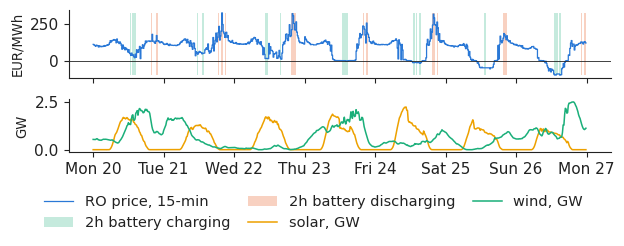

In [10]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

fig, axs = plt.subplots(2, 1, figsize=(6.4, 2.5), sharex=True, gridspec_kw={'height_ratios': [1.3, 1]})
tt = WEEK.index.tz_localize(None)
axs[0].step(tt, WEEK['p'], where='post', color=PAL['RO'], lw=0.9, label='RO price, 15-min')
ch, dc = WEEK['net'] < -1e-6, WEEK['net'] > 1e-6
axs[0].fill_between(tt, WEEK['p'].min(), WEEK['p'].max(), where=ch.values, step='post', color=PAL['HU'], alpha=0.25, lw=0,
                    label='2h battery charging')
axs[0].fill_between(tt, WEEK['p'].min(), WEEK['p'].max(), where=dc.values, step='post', color=PAL['DE_LU'], alpha=0.3, lw=0,
                    label='2h battery discharging')
axs[0].axhline(0, color=INK, lw=0.6)
axs[0].set_ylabel('EUR/MWh', fontsize=9.5)
g = GR['RO'].loc[WEEK.index, ['solar', 'wind_onshore']] / 1000
axs[1].plot(tt, g['solar'], color=PAL['BG'], lw=1.1, label='solar, GW')
axs[1].plot(tt, g['wind_onshore'], color=PAL['HU'], lw=1.1, label='wind, GW')
axs[1].set_ylabel('GW', fontsize=9.5)
axs[1].xaxis.set_major_locator(mdates.DayLocator())
dn = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
axs[1].xaxis.set_major_formatter(FuncFormatter(lambda v, p: dn[mdates.num2date(v).weekday()] + ' ' + str(mdates.num2date(v).day)))
legend_bottom(fig, ncol=3)
fig.tight_layout(rect=(0, 0.2, 1, 1))
plt.savefig('case_week.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()